# 06 — Multi-sample study across scenarios (System I, N3)

The old notebook evaluated the 2-D posterior on 50 replicates of each of the eight scenarios Sc0–Sc7 (400 windows) with the pre-fix simulator. Here: **Sc1–Sc5 and Sc7, 50 windows per scenario (300 windows)**; Sc0 and Sc6 (open loop) are not in the measured-inlet dataset D1
(user decision 1, 2026-11-09). **Production** posterior (measured inlet, notebook 36) on **D1**; the **naive** posterior (nominal inlet, notebook 31) on **D0** (its valid domain) and, as a labelled sensitivity only, on D1.

**Per scenario (rules fixed before running; runbook §2f row g-06):** W1 and CRPS of α and β against the truth (lower is better), bias, 90% coverage, the 2-D coverage (the truth inside the Gaussian-approximation 90% region of the posterior, a joint check that the marginals miss), class accuracy.
1,000 draws per window. **Checks:** finite; n = 50 per scenario; production β coverage ≥ 0.80 in Sc1–Sc4. No decision rule. Sc7 carries a +2 K sensor drift neither posterior models (misspecified by design).


In [1]:
import os, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
import importlib, ws_eval, ws_metrics, ws_phase3, ws_phase3_eval
for _m in (ws_eval, ws_metrics, ws_phase3, ws_phase3_eval):
    importlib.reload(_m)
E = ws_phase3_eval; R = ROOT / "results"; FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True); T0 = time.time()


## 1. Posterior draws and per-scenario metrics

In [2]:
runs = {"production on D1": ("prod", "D1", 61), "naive on D0": ("naive", "D0", 62), "naive on D1 (sensitivity)": ("naive", "D1", 63)}
tabs, samp = {}, {}
for name, (w, dsn, seed) in runs.items():
    s, d, leak = E.draws(w, dsn, 1000, seed=seed)
    assert np.isfinite(s).all() and all((d["scenario_id"] == sc).sum() == 50 for sc in E.SCN), name
    t = E.per_scenario(s, d); t.insert(0, "posterior", name); tabs[name] = t; samp[name] = (s, d)
    print(f"{name}: leakage {leak.mean():.4f}")
allt = pd.concat(tabs.values(), ignore_index=True); allt.to_csv(R / "06_N3_per_scenario.csv", index=False)
prod = tabs["production on D1"]
assert (prod[prod.scenario.isin(["Sc1", "Sc2", "Sc3", "Sc4"])].beta_cov90 >= 0.80).all(), "check failed: production beta coverage"
print("check passed: production beta coverage >= 0.80 in Sc1-Sc4")
cols = ["scenario", "class_acc", "alpha_bias", "alpha_cov90", "alpha_W1", "alpha_CRPS", "beta_bias", "beta_cov90", "beta_W1", "beta_CRPS", "joint_cov90_gauss"]
for name, t in tabs.items():
    print(name); display(t[cols].round(3))


production on D1: leakage 0.0150


naive on D0: leakage 0.0006


naive on D1 (sensitivity): leakage 0.3838
check passed: production beta coverage >= 0.80 in Sc1-Sc4
production on D1


,scenario,class_acc,alpha_bias,alpha_cov90,alpha_W1,alpha_CRPS,beta_bias,beta_cov90,beta_W1,beta_CRPS,joint_cov90_gauss
0,Sc1,0.98,0.016,0.88,0.064,0.033,0.000,0.96,0.047,0.022,0.92
1,Sc2,0.84,0.015,0.90,0.062,0.030,0.007,0.92,0.050,0.025,0.96
2,Sc3,1.00,0.002,0.96,0.028,0.012,-0.006,0.88,0.048,0.025,0.96
3,Sc4,0.92,0.005,0.90,0.044,0.021,-0.001,0.94,0.044,0.020,0.94
4,Sc5,0.98,0.016,0.86,0.063,0.031,0.002,0.96,0.045,0.021,0.94
5,Sc7,0.50,-0.099,0.64,0.116,0.076,-0.394,0.00,0.394,0.378,0.00


naive on D0


,scenario,class_acc,alpha_bias,alpha_cov90,alpha_W1,alpha_CRPS,beta_bias,beta_cov90,beta_W1,beta_CRPS,joint_cov90_gauss
0,Sc1,1.00,0.018,0.92,0.057,0.027,0.001,0.94,0.015,0.007,0.92
1,Sc2,0.98,0.007,0.94,0.058,0.029,-0.002,0.96,0.015,0.008,0.92
2,Sc3,1.00,0.000,0.86,0.031,0.016,0.002,0.94,0.017,0.009,0.92
3,Sc4,0.94,-0.001,0.90,0.042,0.021,-0.000,0.88,0.015,0.008,0.88
4,Sc5,0.98,0.010,0.94,0.061,0.030,0.001,0.90,0.026,0.013,0.92
5,Sc7,0.28,-0.128,0.34,0.136,0.102,-0.383,0.00,0.383,0.373,0.00


naive on D1 (sensitivity)


,scenario,class_acc,alpha_bias,alpha_cov90,alpha_W1,alpha_CRPS,beta_bias,beta_cov90,beta_W1,beta_CRPS,joint_cov90_gauss
0,Sc1,0.60,-0.013,0.56,0.098,0.070,-0.071,0.08,0.250,0.242,0.10
1,Sc2,0.22,-0.004,0.62,0.102,0.073,0.039,0.04,0.284,0.277,0.04
2,Sc3,0.52,-0.011,0.64,0.039,0.026,-0.093,0.02,0.227,0.217,0.04
3,Sc4,0.36,0.003,0.60,0.070,0.047,0.083,0.02,0.255,0.243,0.04
4,Sc5,0.30,-0.041,0.48,0.124,0.097,0.177,0.06,0.263,0.254,0.06
5,Sc7,0.22,-0.131,0.36,0.143,0.109,-0.300,0.08,0.354,0.338,0.06


## 2. Figure: W1 and CRPS of β per scenario; posterior-mean scatter in (α, β)

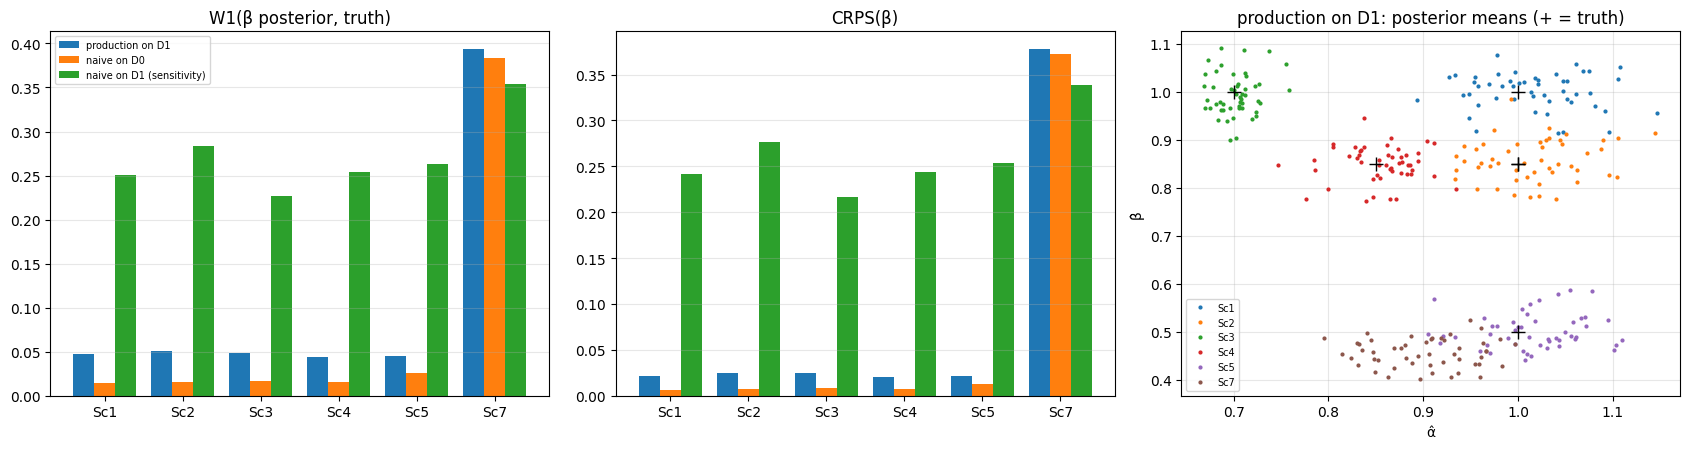

notebook wall time 0.4 min


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
x = np.arange(len(E.SCN)); w = 0.27
for k, (name, t) in enumerate(tabs.items()):
    axes[0].bar(x + (k - 1) * w, t.beta_W1, w, label=name); axes[1].bar(x + (k - 1) * w, t.beta_CRPS, w, label=name)
for ax, ttl in ((axes[0], "W1(β posterior, truth)"), (axes[1], "CRPS(β)")):
    ax.set_xticks(x); ax.set_xticklabels(list(E.SCN.values())); ax.set_title(ttl); ax.grid(alpha=.3, axis="y")
axes[0].legend(fontsize=7)
s, d = samp["production on D1"]; mean = s.mean(1); sid = d["scenario_id"]
for sc, nm in E.SCN.items():
    m = sid == sc; axes[2].plot(mean[m, 0], mean[m, 1], ".", ms=4, label=nm); axes[2].plot(*d["theta"][m][0, 2:], "k+", ms=10)
axes[2].set_xlabel("α̂"); axes[2].set_ylabel("β̂"); axes[2].set_title("production on D1: posterior means (+ = truth)"); axes[2].legend(fontsize=7); axes[2].grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIGS / "06_N3_multi_sample.png", dpi=150); plt.show()
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")


## 6. Interpretation

**Production on D1.** In Sc1–Sc5 the β posterior has W1 0.044–0.050 and CRPS 0.020–0.025 against the truth, β coverage 0.88–0.96, and the 2-D coverage (the truth inside the Gaussian-approximation 90% region) is 0.94–0.96, in line with the marginal coverage: the joint shape adds no hidden miscalibration. The α metrics are W1 0.028–0.064, CRPS 0.012–0.033
(Sc3, α = 0.70, has the narrowest α posterior, sd 0.030 against 0.043–0.058 elsewhere; why was not investigated). Class accuracy 0.84–1.00 (Sc2 is the hard one, β = 0.85 against the 0.90 threshold).

**Naive on D0 (its valid domain).** The same metrics are about three times better for β (W1 0.015–0.026, CRPS 0.007–0.013) with 2-D coverage 0.88–0.92: the sharpness is real and so is the assumption behind it (the inlet is exactly nominal).

**Naive on D1 (sensitivity: the wrong data).** The failure is total and visible in every metric: β W1 0.23–0.28, β coverage 0.02–0.08, 2-D coverage 0.04–0.10, class accuracy 0.22–0.60, and the **prior leakage is 38%** (0.06% on D0 for the same posterior): a posterior asked about data it was not trained for pushes more than a third of its mass outside the prior box. Prior leakage is the
cheapest alarm for a gross mismatch (it is not an alarm for a mild one: the production posterior on D1 leaks 1.5%).

**Sc7.** Misspecified for all three: β W1 0.35–0.39, β coverage 0.00–0.08, 2-D coverage 0.00–0.06; production and naive-on-D0 are equally wrong (bias −0.394 and −0.383).

**Ledger.** Supports: Table 7-type numbers per scenario for the production posterior (W1, CRPS, coverage, accuracy); the statement that the joint (α, β) shape is calibrated. Documents: the naive posterior's collapse on D1 and its prior leakage; Sc7.